# Formulación QUBO en Logística: Problema del Viajante de Comercio (TSP) - 4 Nodos

En este notebook abordaremos el **Problema del Viajante de Comercio** (*Traveling Salesperson Problem* o **TSP**) sobre una red de **4 ciudades** ($A, B, C, D$).

A diferencia del caso de 3 ciudades (donde solo existe una ruta circular posible salvo sentido de giro), en 4 ciudades surgen **3 topologías de ruta cualitativamente distintas**, lo que convierte este escenario en un banco de pruebas representativo de problemas logísticos reales.

### Objetivos de aprendizaje
1. **Comprender la formulación de permutación temporal:** Asignar $N=4$ ciudades en $P=4$ pasos temporales mediante una matriz de variables binarias $x_{v, t}$ de dimensión $4 \times 4 = 16$ variables.
2. **Deducir analíticamente las penalizaciones cuadráticas:** Traducir las restricciones *One-Hot* (una ciudad por paso y cada ciudad visitada una sola vez) en términos de energía QUBO (diagonales lineales y acoplamientos cuadráticos).
3. **Calibrar el parámetro de Lagrange ($\lambda$):** Aprender a dimensionar la penalización $\lambda = 100$ para que las restricciones de factibilidad dominen sobre la minimización de distancias.
4. **Construir y entender la matriz QUBO:** Generar la matriz $Q$ de tamaño $16 \times 16$ en Python usando `collections.defaultdict`.
5. **Resolver con cálculo exacto (`dimod.ExactSolver`):** Explorar exhaustivamente el espacio de $2^{16} = 65.536$ configuraciones y estudiar la **degeneración óctuple** del estado fundamental.
6. **Resolver con recocido simulado (`neal`):** Aplicar el muestreador estocástico local en CPU y contrastarlo con heurísticas clásicas de `networkx`.
7. **Visualización gráfica y reducción de variables (*Gauge Fixing*):** Trazar el ciclo óptimo sobre el mapa y analizar cómo fijar una ciudad de inicio reduce drásticamente el número de variables binarias necesarias.


In [8]:
# Instalación de librerías necesarias (si ejecutas en Google Colab o un entorno nuevo)
!pip install -q dimod dwave-neal networkx matplotlib tabulate

## 1. Formulación matemática del TSP para 4 ciudades

Disponemos de $N = 4$ ciudades: $V = \{A, B, C, D\}$. Para cada par de ciudades $u, v \in V$, conocemos el coste o distancia de desplazamiento $d_{uv}$.

Queremos encontrar el ciclo que visite cada ciudad exactamente una vez y regrese al origen minimizando el coste total.

### Variables de decisión binarias
Definimos una variable binaria por cada combinación de ciudad $v$ y paso temporal $t$:
$$x_{v, t} \in \{0, 1\} \quad \text{donde } x_{v, t} = 1 \iff \text{la ciudad } v \text{ se visita en el instante } t \in \{0, 1, 2, 3\}$$

Para $N=4$, se requieren **$4 \times 4 = 16$ variables binarias**. El espacio total de configuraciones posibles es:
$$2^{16} = 65.536 \text{ estados}$$

### Restricciones de permutación (*One-Hot*)

1. **Cada ciudad $v$ debe visitarse exactamente una vez:**
   $$\sum_{t=0}^{N-1} x_{v, t} = 1 \quad \forall v \in V$$
   Penalización cuadrática:
   $$\text{Penalización}_{\text{ciudad } v} = \lambda \left( \sum_{t=0}^{N-1} x_{v, t} - 1 \right)^2$$
   Expandiendo el cuadrado y aplicando la propiedad binaria $x^2 = x$:
   $$\lambda \left( \sum_t x_{v, t}^2 + 2 \sum_{t_1 < t_2} x_{v, t_1} x_{v, t_2} - 2 \sum_t x_{v, t} + 1 \right) = -\lambda \sum_t x_{v, t} + 2\lambda \sum_{t_1 < t_2} x_{v, t_1} x_{v, t_2} + \lambda$$

2. **En cada instante temporal $t$ se debe visitar exactamente una ciudad:**
   $$\sum_{v \in V} x_{v, t} = 1 \quad \forall t \in \{0, \dots, N-1\}$$
   Penalización cuadrática:
   $$\text{Penalización}_{\text{tiempo } t} = \lambda \left( \sum_{v \in V} x_{v, t} - 1 \right)^2 = -\lambda \sum_v x_{v, t} + 2\lambda \sum_{u < v} x_{u, t} x_{v, t} + \lambda$$

### Función objetivo: Distancia total del ciclo
Si en el paso $t$ estamos en $u$ ($x_{u, t} = 1$) y en el siguiente paso $(t+1) \pmod N$ nos movemos a $v$ ($x_{v, (t+1) \pmod N} = 1$), pagamos el coste $d_{uv}$:
$$H_{\text{distancia}} = \sum_{t=0}^{N-1} \sum_{u \in V} \sum_{v \in V, v \ne u} d_{uv} \cdot x_{u, t} \cdot x_{v, (t+1) \pmod N}$$

### Traducción directa a la matriz QUBO $Q$
Para formular como $\min x^T Q x$:
* **Términos lineales (diagonal $Q_{ii}$):** Restamos $\lambda$ por cada restricción de fila y columna a la que pertenece la variable:
  $$Q[((v, t), (v, t))] \mathrel{-}= 2\lambda$$
* **Términos cuadráticos de exclusión (fuera de diagonal):** Sumamos $2\lambda$ para parejas que violen las restricciones:
  $$Q[((v, t_1), (v, t_2))] \mathrel{+}= 2\lambda \quad (t_1 < t_2)$$
  $$Q[((u, t), (v, t))] \mathrel{+}= 2\lambda \quad (u < v)$$
* **Términos cuadráticos de distancia:** Sumamos la distancia $d_{uv}$ al acoplamiento temporal:
  $$Q[((u, t), (v, (t+1) \pmod N))] \mathrel{+}= d_{uv}$$


Ciudades: ['A', 'B', 'D', 'C'] (N = 4)
Total de variables binarias requeridas: 4 x 4 = 16 variables
Espacio de configuraciones totales: 2^16 = 65,536 estados


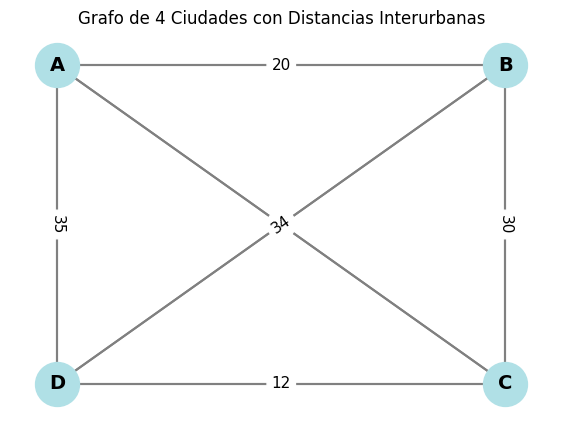

In [9]:
import networkx as nx
import matplotlib.pyplot as plt

# Definición del grafo con 4 ciudades y sus distancias
G = nx.DiGraph()
G.add_weighted_edges_from({
    ("A", "B", 20), ("A", "C", 42), ("A", "D", 35),
    ("B", "A", 20), ("B", "C", 30), ("B", "D", 34),
    ("C", "A", 42), ("C", "B", 30), ("C", "D", 12),
    ("D", "A", 35), ("D", "B", 34), ("D", "C", 12)
})

N = G.number_of_nodes()
print(f"Ciudades: {list(G.nodes())} (N = {N})")
print(f"Total de variables binarias requeridas: {N} x {N} = {N**2} variables")
print(f"Espacio de configuraciones totales: 2^{N**2} = {2**(N**2):,} estados")

# Visualización inicial del grafo completo
plt.figure(figsize=(7, 5))
node_layout = {'A': (-1, 1), 'B': (1, 1), 'C': (1, -1), 'D': (-1, -1)}

nx.draw_networkx_nodes(G, node_layout, node_color='powderblue', node_size=1000)
nx.draw_networkx_labels(G, node_layout, font_size=14, font_weight='bold')

# Etiquetas de pesos en aristas no dirigidas
edge_labels = {(u, v): f"{d['weight']}" for u, v, d in G.edges(data=True) if u < v}
nx.draw_networkx_edges(G, node_layout, edge_color='gray', width=1.5, arrows=False)
nx.draw_networkx_edge_labels(G, node_layout, edge_labels=edge_labels, font_size=11)

plt.title("Grafo de 4 Ciudades con Distancias Interurbanas")
plt.axis('off')
plt.show()


## 2. Construcción de la matriz QUBO

Elegimos un multiplicador de Lagrange $\lambda = 100.0$:
* En optimización cuadrática, la regla empírica es fijar $\lambda$ entre el 75% y el 150% del valor total de la función objetivo estimada.
* Al ser $\lambda = 100 > \max_{(u,v)} d_{uv} = 42$, el optimizador nunca aceptará romper una restricción (multa de $\ge 100$) para atajar distancias.


In [10]:
from collections import defaultdict

lagrange = 100.0
Q = defaultdict(float)

# 1. Función objetivo: Distancia acumulada entre ciudades consecutivas
for u in G:
    for v in G:
        if u == v:
            continue
        # Coste del trayecto si existe arista, o penalización si no existiera
        value = G[u][v]["weight"] if G.has_edge(u, v) else lagrange
        for t in range(N):
            next_t = (t + 1) % N
            Q[((u, t), (v, next_t))] += value

# 2. Restricción 1: Cada ciudad visitada exactamente una vez (por filas)
for node in G:
    for t_1 in range(N):
        Q[((node, t_1), (node, t_1))] -= lagrange
        for t_2 in range(t_1 + 1, N):
            Q[((node, t_1), (node, t_2))] += 2 * lagrange

# 3. Restricción 2: Cada posición temporal ocupada por una sola ciudad (por columnas)
for t in range(N):
    node_list = list(G.nodes())
    for i, node_1 in enumerate(node_list):
        Q[((node_1, t), (node_1, t))] -= lagrange
        for node_2 in node_list[i + 1:]:
            Q[((node_1, t), (node_2, t))] += 2 * lagrange

print(f"Total de pares de interacción no nulos en Q: {len(Q)}")
print("\nMuestra de coeficientes generados en Q:")
for k, v in list(Q.items())[:8]:
    tipo = "Diagonal (lineal)" if k[0] == k[1] else "Acoplamiento (cuadrático)"
    print(f"  Q[{k[0]}, {k[1]}] = {v:6.1f}  ({tipo})")


Total de pares de interacción no nulos en Q: 112

Muestra de coeficientes generados en Q:
  Q[('A', 0), ('B', 1)] =   20.0  (Acoplamiento (cuadrático))
  Q[('A', 1), ('B', 2)] =   20.0  (Acoplamiento (cuadrático))
  Q[('A', 2), ('B', 3)] =   20.0  (Acoplamiento (cuadrático))
  Q[('A', 3), ('B', 0)] =   20.0  (Acoplamiento (cuadrático))
  Q[('A', 0), ('D', 1)] =   35.0  (Acoplamiento (cuadrático))
  Q[('A', 1), ('D', 2)] =   35.0  (Acoplamiento (cuadrático))
  Q[('A', 2), ('D', 3)] =   35.0  (Acoplamiento (cuadrático))
  Q[('A', 3), ('D', 0)] =   35.0  (Acoplamiento (cuadrático))


## 3. Resolución con cálculo exacto (`dimod.ExactSolver`)

Con 16 variables, evaluar exhaustivamente las $65.536$ configuraciones posibles en CPU toma una fracción de segundo en `dimod.ExactSolver`.

Esto nos permite encontrar **con certeza matemática absoluta** el mínimo global y analizar las simetrías inherentes al problema.


In [11]:
import dimod
import time

exact_sampler = dimod.ExactSolver()

t0 = time.time()
response_exact = exact_sampler.sample_qubo(Q)
t_exact = time.time() - t0

min_energy = response_exact.first.energy
print(f"Tiempo de búsqueda exhaustiva (65.536 estados): {t_exact:.3f} s")
print(f"Energía mínima encontrada: {min_energy:.1f}")

# Filtramos todas las soluciones que alcanzan el mínimo global
optimal_samples = [s for s, e in response_exact.data(fields=['sample', 'energy']) if e == min_energy]
print(f"Número de configuraciones en el estado fundamental: {len(optimal_samples)}")


Tiempo de búsqueda exhaustiva (65.536 estados): 0.119 s
Energía mínima encontrada: -703.0
Número de configuraciones en el estado fundamental: 8


In [12]:
print(f"{'Solución':<10s} | {'Ruta Cíclica Completa':<28s} | {'Coste Distancia':<15s} | {'Energía QUBO'}")
print("-" * 75)

for idx, sample in enumerate(optimal_samples, 1):
    # Reconstruimos la ruta temporal
    cycle = [None] * (N + 1)
    for (city, step), val in sample.items():
        if val == 1:
            cycle[step] = city
    cycle[-1] = cycle[0]
    
    # Calculamos el coste real de la ruta en el grafo
    cost = sum(G[n][nbr]["weight"] for n, nbr in nx.utils.pairwise(cycle))
    ruta_str = " -> ".join(cycle)
    print(f"Solución {idx:<2d} | {ruta_str:<28s} | {cost:^15.1f} | {min_energy:.1f}")


Solución   | Ruta Cíclica Completa        | Coste Distancia | Energía QUBO
---------------------------------------------------------------------------
Solución 1  | A -> B -> C -> D -> A        |      97.0       | -703.0
Solución 2  | B -> A -> D -> C -> B        |      97.0       | -703.0
Solución 3  | B -> C -> D -> A -> B        |      97.0       | -703.0
Solución 4  | D -> C -> B -> A -> D        |      97.0       | -703.0
Solución 5  | A -> D -> C -> B -> A        |      97.0       | -703.0
Solución 6  | C -> B -> A -> D -> C        |      97.0       | -703.0
Solución 7  | C -> D -> A -> B -> C        |      97.0       | -703.0
Solución 8  | D -> A -> B -> C -> D        |      97.0       | -703.0


### Discusión didáctica: ¿Por qué hay exactamente 8 soluciones óptimas?

Observa detenidamente las 8 rutas obtenidas:
Todas recorren exactamente la misma secuencia de aristas: $(A, B)$, $(B, C)$, $(C, D)$ y $(D, A)$, cuyo coste total es:
$$\text{Coste} = 20 + 30 + 12 + 35 = 97$$

La multiplicidad $8$ surge de dos propiedades de simetría física:
1. **Simetría cíclica (4 traslaciones temporales):** La ruta puede comenzar en cualquiera de las 4 ciudades ($A, B, C$ o $D$).
2. **Simetría de reversión (2 sentidos de giro):** En un grafo simétrico, recorrer el anillo en sentido horario ($A \to B \to C \to D \to A$) cuesta lo mismo que en sentido antihorario ($A \to D \to C \to B \to A$).
$$4 \text{ inicios} \times 2 \text{ direcciones} = 8 \text{ soluciones equivalentes}$$

### Verificación matemática de la energía ($-703.0$):
* En una ruta válida, exactamente 4 variables valen $1$.
* Cada variable recibe $-\lambda = -100$ por la fila y $-\lambda = -100$ por la columna:
  $$\text{Términos lineales} = 4 \times (-200) = -800$$
* Las 4 aristas transitadas suman el coste de la ruta: $+97$.
$$\text{Energía total} = -800 + 97 = -703.0$$

### Comparación con las otras rutas posibles:
En 4 ciudades existen solo 3 topologías de ciclo distintas:
1. **$A - B - C - D - A$:** Coste $20 + 30 + 12 + 35 = \mathbf{97}$ (**ÓPTIMA**)
2. **$A - B - D - C - A$:** Coste $20 + 34 + 12 + 42 = 108$
3. **$A - C - B - D - A$:** Coste $42 + 30 + 34 + 35 = 141$

El algoritmo discriminó correctamente la combinación de menor coste global.


## 4. Resolución heurística con Neal (`SimulatedAnnealingSampler`)

Para redes logísticas reales con 20 o 50 ciudades, evaluar $2^{N^2}$ estados es imposible por fuerza bruta.

`neal.SimulatedAnnealingSampler` es el algoritmo estocástico de recocido simulado en CPU. Ejecutamos 100 lecturas y contrastamos con la aproximación heurística clásica de `networkx`:


In [13]:
import neal
from networkx.algorithms import approximation as approx

# 1. Recocido simulado sobre la matriz QUBO con Neal
sa_sampler = neal.SimulatedAnnealingSampler()

t0 = time.time()
response_sa = sa_sampler.sample_qubo(Q, num_reads=100)
t_sa = time.time() - t0

best_sa = response_sa.first.sample
sa_cycle = [None] * (N + 1)
for (city, step), val in best_sa.items():
    if val == 1:
        sa_cycle[step] = city
sa_cycle[-1] = sa_cycle[0]
sa_cost = sum(G[n][nbr]["weight"] for n, nbr in nx.utils.pairwise(sa_cycle))

print(f"=== 1. Neal Simulated Annealing (QUBO) ===")
print(f"Tiempo: {t_sa:.3f} s")
print(f"Ruta obtenida: {' -> '.join(sa_cycle)}")
print(f"Coste de la ruta: {sa_cost:.1f}")
print(f"Energía obtenida: {response_sa.first.energy:.1f}")

# 2. Aproximación clásica de NetworkX
nx_cycle = approx.simulated_annealing_tsp(G, "greedy", source="A")
nx_cost = sum(G[n][nbr]["weight"] for n, nbr in nx.utils.pairwise(nx_cycle))

print(f"\n=== 2. NetworkX Simulated Annealing ===")
print(f"Ruta obtenida: {' -> '.join(nx_cycle)}")
print(f"Coste de la ruta: {nx_cost:.1f}")


=== 1. Neal Simulated Annealing (QUBO) ===
Tiempo: 0.039 s
Ruta obtenida: C -> D -> A -> B -> C
Coste de la ruta: 97.0
Energía obtenida: -703.0

=== 2. NetworkX Simulated Annealing ===
Ruta obtenida: A -> B -> C -> D -> A
Coste de la ruta: 97.0


## 5. Visualización de la ruta óptima de 4 ciudades

Trazamos sobre el plano la solución óptima, mostrando en color rojo y con flechas dirigidas el itinerario de mínimo coste:


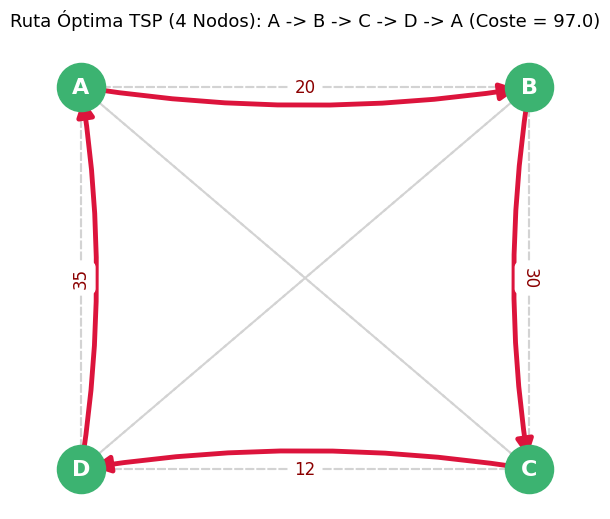

In [14]:
best_sample = response_exact.first.sample
best_cycle = [None] * (N + 1)
for (city, step), val in best_sample.items():
    if val == 1:
        best_cycle[step] = city
best_cycle[-1] = best_cycle[0]

best_cost = sum(G[n][nbr]["weight"] for n, nbr in nx.utils.pairwise(best_cycle))
tour_edges = list(nx.utils.pairwise(best_cycle))

plt.figure(figsize=(7, 6))
nx.draw_networkx_nodes(G, node_layout, node_color='mediumseagreen', node_size=1200)
nx.draw_networkx_labels(G, node_layout, font_size=16, font_weight='bold', font_color='white')

# Aristas de fondo
nx.draw_networkx_edges(G, node_layout, edge_color='lightgray', width=1.5, style='dashed', arrows=False)

# Aristas del recorrido óptimo con flechas dirigidas
nx.draw_networkx_edges(
    G, node_layout,
    edgelist=tour_edges,
    edge_color='crimson',
    width=3.5,
    arrows=True,
    arrowsize=25,
    arrowstyle='-|>',
    connectionstyle='arc3,rad=0.08'
)

# Etiquetas con las distancias de las aristas del tour
tour_labels = {(u, v): f"{G[u][v]['weight']}" for u, v in tour_edges}
nx.draw_networkx_edge_labels(G, node_layout, edge_labels=tour_labels, font_size=12, font_color='darkred')

plt.title(f"Ruta Óptima TSP (4 Nodos): {' -> '.join(best_cycle)} (Coste = {best_cost:.1f})", fontsize=13, pad=15)
plt.axis('off')
plt.show()


## 6. Optimización avanzada: Reducción de variables (*Gauge Fixing*)

Un obstáculo común al llevar el TSP a computadores cuánticos reales (QPUs) es la escasez de cúbits: $N=4$ requiere 16 variables, $N=10$ requiere 100, etc.

### ¿Cómo ahorrar variables?
Dado que cualquier circuito cerrado puede comenzar arbitrariamente en la ciudad $A$ en el instante inicial $t=0$:
* Fijamos **$x_{A, 0} = 1$**.
* Esto elimina la necesidad de variables para $A$ en $t > 0$ y prohíbe que cualquier otra ciudad ocupe $t=0$.
* Reducimos el problema a **$(N-1)^2 = 3^2 = 9$ variables binarias** (¡un ahorro del 44% en variables y pasamos de $65.536$ a solo $512$ estados!).
* Además, **elimina la degeneración cíclica**, dejando únicamente 2 soluciones óptimas (sentido horario y antihorario):


In [15]:
# Demostración de Gauge Fixing (fijar A en t=0)
cities = ["B", "C", "D"] # Sólo variamos las otras 3 ciudades
steps = [1, 2, 3]

Q_reduced = defaultdict(float)
lagrange_gf = 100.0

# 1. Distancias desde y hacia el nodo fijado A
for v in cities:
    # Tramo inicial: A (paso 0) -> v (paso 1)
    Q_reduced[((v, 1), (v, 1))] += G["A"][v]["weight"]
    # Tramo final: v (paso 3) -> A (paso 0)
    Q_reduced[((v, 3), (v, 3))] += G[v]["A"]["weight"]

# 2. Distancias intermedias entre ciudades restantes
for u in cities:
    for v in cities:
        if u == v:
            continue
        for step in [1, 2]:
            Q_reduced[((u, step), (v, step + 1))] += G[u][v]["weight"]

# 3. Restricciones One-Hot para las 3 ciudades restantes
for c in cities:
    for s1 in steps:
        Q_reduced[((c, s1), (c, s1))] -= lagrange_gf
        for s2 in [s for s in steps if s > s1]:
            Q_reduced[((c, s1), (c, s2))] += 2 * lagrange_gf

for s in steps:
    for i, c1 in enumerate(cities):
        Q_reduced[((c1, s), (c1, s))] -= lagrange_gf
        for c2 in cities[i + 1:]:
            Q_reduced[((c1, s), (c2, s))] += 2 * lagrange_gf

# Resolver el QUBO reducido (sólo 9 variables)
res_reduced = exact_sampler.sample_qubo(Q_reduced)
opt_reduced = [s for s, e in res_reduced.data(fields=['sample', 'energy']) if e == res_reduced.first.energy]

print(f"Variables en QUBO reducido: {len({v for pair in Q_reduced.keys() for v in pair})} (vs 16 original)")
print(f"Soluciones óptimas tras Gauge Fixing: {len(opt_reduced)} (se eliminó la simetría cíclica)")

for i, s in enumerate(opt_reduced, 1):
    c_route = ["A"] + [None] * 3 + ["A"]
    for (city, step), val in s.items():
        if val == 1:
            c_route[step] = city
    c_cost = sum(G[u][v]["weight"] for u, v in nx.utils.pairwise(c_route))
    print(f"  Ruta {i}: {' -> '.join(c_route)} | Coste: {c_cost}")


Variables en QUBO reducido: 9 (vs 16 original)
Soluciones óptimas tras Gauge Fixing: 2 (se eliminó la simetría cíclica)
  Ruta 1: A -> B -> C -> D -> A | Coste: 97
  Ruta 2: A -> D -> C -> B -> A | Coste: 97


## 7. Conclusiones y buenas prácticas

1. **Topologías no triviales:** Al trabajar con 4 o más nodos, el optimizador no solo busca un ciclo cualquiera, sino que debe discriminar activamente entre alternativas topológicas competidoras (en este caso, 97 vs 108 vs 141).
2. **Degeneración del estado fundamental:** En optimización combinatoria basada en Hamiltonianos, las simetrías intrínsecas (rotación temporal y sentido de recorrido) generan estados fundamentales múltiples (*degenerate ground states*).
3. **Optimización de recursos cuánticos:** Técnicas como *Gauge Fixing* son esenciales para reducir el número de cúbits y simplificar la conectividad en arquitecturas cuánticas actuales (NISQ).
